In [18]:
import pandas as pd
import torch
import json
import random
import matplotlib.pyplot as plt
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cpu')

In [2]:
extra = {'vocab.json': ''}
model = torch.jit.load('reasoning_model_full.pt', map_location=device, _extra_files=extra)
print(extra['vocab.json'])
model.eval()

char_to_index = json.loads(extra['vocab.json'])
index_to_char = {i: c for c, i in char_to_index.items()}
print('Loaded model on', device)


def generate(prompt, max_chars=60):
    unknown = [c for c in prompt if c not in char_to_index]
    if unknown:
        print(f'Unknown chars: {unknown}')
        return

    generated = list(prompt)
    print(generated)
    with torch.no_grad():
        for _ in range(max_chars):
            #print(_)
            print(generated)
            tokens = torch.tensor([char_to_index[c] for c in generated], device=device)
            #print(model(tokens)[-1].argmax().item())
            next_token = model(tokens)[-1].argmax().item()
            next_char = index_to_char[next_token]
            if next_char == '\n':
                break
            generated.append(next_char)

    output = ''.join(generated)
    print(f'{prompt}   ->  {output}')
    return output

generate('35+21=')

b'{"\\n": 0, "+": 1, ",": 2, "0": 3, "1": 4, "2": 5, "3": 6, "4": 7, "5": 8, "6": 9, "7": 10, "8": 11, "9": 12, "=": 13, "c": 14, "|": 15}'
Loaded model on cpu
['3', '5', '+', '2', '1', '=']
['3', '5', '+', '2', '1', '=']
['3', '5', '+', '2', '1', '=', '|']
['3', '5', '+', '2', '1', '=', '|', '5']
['3', '5', '+', '2', '1', '=', '|', '5', '+']
['3', '5', '+', '2', '1', '=', '|', '5', '+', '1']
['3', '5', '+', '2', '1', '=', '|', '5', '+', '1', '=']
['3', '5', '+', '2', '1', '=', '|', '5', '+', '1', '=', '6']
['3', '5', '+', '2', '1', '=', '|', '5', '+', '1', '=', '6', 'c']
['3', '5', '+', '2', '1', '=', '|', '5', '+', '1', '=', '6', 'c', '0']
['3', '5', '+', '2', '1', '=', '|', '5', '+', '1', '=', '6', 'c', '0', ',']
['3', '5', '+', '2', '1', '=', '|', '5', '+', '1', '=', '6', 'c', '0', ',', '3']
['3', '5', '+', '2', '1', '=', '|', '5', '+', '1', '=', '6', 'c', '0', ',', '3', '+']
['3', '5', '+', '2', '1', '=', '|', '5', '+', '1', '=', '6', 'c', '0', ',', '3', '+', '2']
['3', '5', '+', 

'35+21=|5+1=6c0,3+2=5c0|56'

In [26]:
char_to_index

{'\n': 0,
 '+': 1,
 ',': 2,
 '0': 3,
 '1': 4,
 '2': 5,
 '3': 6,
 '4': 7,
 '5': 8,
 '6': 9,
 '7': 10,
 '8': 11,
 '9': 12,
 '=': 13,
 'c': 14,
 '|': 15}

In [3]:
def hidden_states(text):
    tokens = torch.tensor([char_to_index[c] for c in text], device=device)
    
    with torch.no_grad():
        x = model.embedding[tokens]+ model.pos[:len(tokens)]
        for block in model.blocks.children():
            print('1')
            x = block(x)
            #print(x)
        return x

In [4]:
text = '35+21=|'
h = hidden_states(text)
print(h.shape)

1
torch.Size([7, 128])


In [5]:
# print(torch.allclose(h @ model.out_w + model.out_b, model(tokens), atol=1e-4))

In [6]:
# a = h @ model.out_w + model.out_b
# a.shape

In [7]:
def cot_trace(a, b):
    da = [int(c) for c in str(a)][::-1]
    db = [int(c) for c in str(b)][::-1]
    n = max(len(da), len(db))
    da += [0] * (n - len(da))
    db += [0] * (n - len(db))
    steps, carry = [], 0
    for i in range(n):
        s = da[i] + db[i] + carry
        new_carry = s // 10
        if carry:
            steps.append(f'{da[i]}+{db[i]}+{carry}={s}c{new_carry}')
        else:
            steps.append(f'{da[i]}+{db[i]}={s}c{new_carry}')
        carry = new_carry
    return ','.join(steps)

MAX_DIGITS = 2
lines = []
for _ in range(2000):
    a = random.randint(0, 10**MAX_DIGITS - 1)
    b = random.randint(0, 10**MAX_DIGITS - 1)
    lines.append(f'{a}+{b}=|{cot_trace(a, b)}|{a+b}')

corpus = '\n'.join(lines)
# print(corpus[:300])  # preview

chars = sorted(set(corpus))
vocab = chars
char_to_index = {c: i for i, c in enumerate(vocab)}
index_to_char = {i: c for c, i in char_to_index.items()}
vocab_size = len(vocab)
vocab_size

16

In [8]:
activation_lst = []
context = []
for i in lines:
    #print(i)
    h = hidden_states(i)
    print(i, h.shape, len(i))
    activation_lst.append(h)

acts_concat = torch.cat(activation_lst)             
print(acts_concat.shape)

1
5+18=|5+8=13c1,0+1+1=2c0|23 torch.Size([27, 128]) 27
1
36+5=|6+5=11c1,3+0+1=4c0|41 torch.Size([27, 128]) 27
1
95+56=|5+6=11c1,9+5+1=15c1|151 torch.Size([30, 128]) 30
1
15+14=|5+4=9c0,1+1=2c0|29 torch.Size([25, 128]) 25
1
12+42=|2+2=4c0,1+4=5c0|54 torch.Size([25, 128]) 25
1
58+79=|8+9=17c1,5+7+1=13c1|137 torch.Size([30, 128]) 30
1
97+26=|7+6=13c1,9+2+1=12c1|123 torch.Size([30, 128]) 30
1
71+77=|1+7=8c0,7+7=14c1|148 torch.Size([27, 128]) 27
1
47+63=|7+3=10c1,4+6+1=11c1|110 torch.Size([30, 128]) 30
1
7+7=|7+7=14c1|14 torch.Size([16, 128]) 16
1
49+94=|9+4=13c1,4+9+1=14c1|143 torch.Size([30, 128]) 30
1
72+36=|2+6=8c0,7+3=10c1|108 torch.Size([27, 128]) 27
1
15+84=|5+4=9c0,1+8=9c0|99 torch.Size([25, 128]) 25
1
58+64=|8+4=12c1,5+6+1=12c1|122 torch.Size([30, 128]) 30
1
16+45=|6+5=11c1,1+4+1=6c0|61 torch.Size([28, 128]) 28
1
30+97=|0+7=7c0,3+9=12c1|127 torch.Size([27, 128]) 27
1
81+18=|1+8=9c0,8+1=9c0|99 torch.Size([25, 128]) 25
1
32+99=|2+9=11c1,3+9+1=13c1|131 torch.Size([30, 128]) 30
1
0+58=

In [9]:
class SparseAutoencoder(torch.nn.Module):
    def __init__(self, d_model=128, d_features = 512):
        super().__init__()
        self.encoder = torch.nn.Linear(d_model, d_features)
        self.decoder = torch.nn.Linear(d_features, d_model)

    def forward(self, x):
        features = torch.relu(self.encoder(x))
        reconstruction = self.decoder(features)
        return features, reconstruction

sae = SparseAutoencoder().to(device)  

In [10]:
optimizer = torch.optim.Adam(sae.parameters(), lr=1e-3)
l1_coeff = 3e-3

In [11]:
len(acts_concat)

54026

In [12]:
def a():
    return 6,7

k1,k2 = a()
k1

6

In [13]:
total_var = acts_concat.var(dim=0).mean()
for epoch in range(25):
    order = torch.randperm(len(acts_concat))
    for i in range(0, len(acts_concat), 250):
        batch = acts_concat[order[i:i + 250]]
        f, recon = sae(batch)
        #print(f.shape, recon.shape)
        mse = ((recon-batch)**2).mean()
        sparsity = f.abs().sum(dim=1).mean()
        loss = mse + sparsity * l1_coeff
        print('loss-', loss, 'sparsity-', sparsity, 'mse-', mse)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

    with torch.no_grad():
        f2, recon2 = sae(acts_concat)
        explained = 1 - ((recon2 - acts_concat) ** 2).mean() / total_var
        active = (f2 > 0).float().sum(dim=1).mean()
        dead = ((f2 > 0).sum(dim=0) == 0).sum()
        
    print('epoch-', epoch, 'active-', active, 'dead-', dead, 'explained-', explained)  

loss- tensor(1.1322, grad_fn=<AddBackward0>) sparsity- tensor(100.6809, grad_fn=<MeanBackward0>) mse- tensor(0.8301, grad_fn=<MeanBackward0>)
loss- tensor(0.9700, grad_fn=<AddBackward0>) sparsity- tensor(91.6481, grad_fn=<MeanBackward0>) mse- tensor(0.6950, grad_fn=<MeanBackward0>)
loss- tensor(0.9779, grad_fn=<AddBackward0>) sparsity- tensor(93.9987, grad_fn=<MeanBackward0>) mse- tensor(0.6959, grad_fn=<MeanBackward0>)
loss- tensor(0.9132, grad_fn=<AddBackward0>) sparsity- tensor(90.4242, grad_fn=<MeanBackward0>) mse- tensor(0.6420, grad_fn=<MeanBackward0>)
loss- tensor(0.8284, grad_fn=<AddBackward0>) sparsity- tensor(85.7111, grad_fn=<MeanBackward0>) mse- tensor(0.5713, grad_fn=<MeanBackward0>)
loss- tensor(0.7952, grad_fn=<AddBackward0>) sparsity- tensor(84.4795, grad_fn=<MeanBackward0>) mse- tensor(0.5418, grad_fn=<MeanBackward0>)
loss- tensor(0.7526, grad_fn=<AddBackward0>) sparsity- tensor(83.0006, grad_fn=<MeanBackward0>) mse- tensor(0.5036, grad_fn=<MeanBackward0>)
loss- tensor

In [14]:
order = torch.randperm(len(acts_concat))
order

tensor([13901, 10123, 53078,  ..., 32632, 24020, 10444])

In [15]:
batch.shape

torch.Size([26, 128])

In [16]:
contexts = []
for line in lines:
    for pos in range(len(line)):
        contexts.append((line, pos))

print(len(contexts), len(acts_concat))      # these two must be equal

with torch.no_grad():
    all_feats, _ = sae(acts_concat)         # feature values for every row

54026 54026


t 9
6
1
h tensor([-0.7453, -0.1573,  0.3126,  0.5804,  1.0442, -0.1342,  0.0749,  0.8833,
         2.0561, -1.8629,  1.7679,  0.2843,  0.2481, -0.1998,  0.7925,  0.1179,
        -0.2601,  0.2526, -0.3261,  0.2176,  1.5535, -0.1552, -0.4616, -0.1701,
        -0.0534, -0.3727, -0.3011, -0.0419, -0.3457, -0.1113, -0.2068, -1.6195,
         0.2591, -0.7392,  0.1252, -0.3601, -0.8579,  0.8379, -1.8612, -1.9290,
         0.5953, -0.3279,  2.7321,  0.0088, -0.3499,  0.3556, -0.4694,  0.3216,
         0.1387, -1.2048, -2.0653,  0.8500,  2.1760,  0.0209, -0.2680,  0.3742,
         0.1892, -0.2277, -0.0454, -2.0005,  0.2021, -0.8225,  1.3347,  1.1723,
         0.3680,  0.6390, -0.0443, -0.5112,  0.5068, -1.2182, -1.1852,  2.8058,
         0.3414,  0.0245, -0.8809,  1.2760, -0.2895,  2.4181,  0.9259, -1.4926,
         0.8049, -2.0525,  0.1664,  0.1310,  0.6571, -0.1467,  0.4299,  0.1905,
        -0.3372,  0.8606,  3.0222,  0.1724, -0.9117, -2.1240, -0.0345, -1.5684,
         0.0442, -0.2176, -0.3

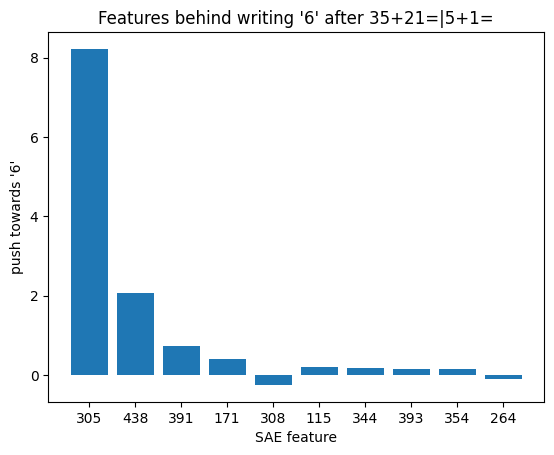

In [25]:
text = '35+21=|5+1='
with torch.no_grad():
    tokens = torch.tensor([char_to_index[c] for c in text], device=device)
    t = model(tokens)[-1].argmax().item()
    print('t', t)
    target = index_to_char[t]
    print(target)
    h = hidden_states(text)[-1]  
    print('h',h, h.shape)
    f, _ = sae(h)                                       
    print('f',f.shape)
    push = sae.decoder.weight.T @ model.out_w[:, t]      # each feature's push towards target
    contrib = f * push

active = (f > 0).nonzero().flatten().tolist()
top = sorted(active, key=lambda j: abs(contrib[j].item()), reverse=True)[:10]

print('model writes:', target, '| active features:', len(active))
plt.bar([str(j) for j in top], [contrib[j].item() for j in top])
plt.xlabel('SAE feature')
plt.ylabel("push towards '" + target + "'")
plt.title("Features behind writing '" + target + "' after " + text)
plt.show()

t 9
6
1
h tensor([-1.2603, -0.2969,  0.2261,  0.8455, -0.3067, -0.3183,  0.2400,  0.4261,
         1.8706, -2.5798,  1.5952, -0.1255, -0.1910, -0.0963,  0.3495,  0.1235,
         0.0430,  0.1109,  0.2548,  0.2446,  2.1811, -0.0803, -0.7700, -0.1769,
         0.0853, -0.5454,  0.4043, -0.1147, -0.4548, -0.0135,  0.6544, -1.8970,
         0.1755, -1.0330,  0.0635, -1.7214, -1.0812,  0.2339, -1.1391, -1.7241,
         0.5360, -0.2598,  1.9037,  0.0344, -0.5433,  0.0389,  0.5667,  0.7017,
        -0.1347, -0.4416, -1.4611, -0.6994,  1.3819,  0.2326, -0.1273,  0.4784,
        -0.0338,  0.0478,  0.0135, -2.2146, -0.4130,  0.2332,  1.1747,  1.2558,
         0.4890,  0.4559,  0.0344, -0.3900, -0.9262, -0.3066, -1.1575,  3.7786,
         0.1254,  0.3071, -0.5364,  1.4481, -0.0278,  2.8445,  0.8624, -1.7436,
         0.8496, -2.1972, -0.0345, -0.0379,  0.3014,  0.3496,  0.2988,  0.1621,
        -0.3889,  0.3018,  2.3166,  0.1759, -1.0163, -0.8110, -0.0056, -0.9627,
        -0.0394,  0.2638, -1.2

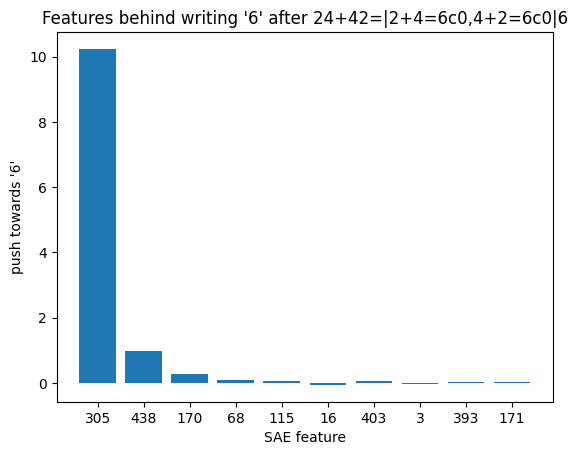

In [31]:
text = '24+42=|2+4=6c0,4+2=6c0|6'
with torch.no_grad():
    tokens = torch.tensor([char_to_index[c] for c in text], device=device)
    t = model(tokens)[-1].argmax().item()
    print('t', t)
    target = index_to_char[t]
    print(target)
    h = hidden_states(text)[-1]  
    print('h',h, h.shape)
    f, _ = sae(h)                                       
    print('f',f.shape)
    push = sae.decoder.weight.T @ model.out_w[:, t]    
    contrib = f * push

active = (f > 0).nonzero().flatten().tolist()
top = sorted(active, key=lambda j: abs(contrib[j].item()), reverse=True)[:10]

print('model writes:', target, '| active features:', len(active))
plt.bar([str(j) for j in top], [contrib[j].item() for j in top])
plt.xlabel('SAE feature')
plt.ylabel("push towards '" + target + "'")
plt.title("Features behind writing '" + target + "' after " + text)
plt.show()

In [48]:
import collections

with torch.no_grad():
    all_feats, _ = sae(acts_concat)

mapping = []
for j in range(all_feats.shape[1]):
    #print(j)
    v = all_feats[:, j]
    on = (v > 0).nonzero().flatten().tolist()
    #print('on', len(on), on)
    if not on:
        continue                                          # dead feature
    nxt = collections.Counter()
    for i in on:
        line, pos = contexts[i]
        nxt[line[pos + 1] if pos + 1 < len(line) else 'END'] += v[i].item()
    char, mass = nxt.most_common(1)[0]
    mapping.append((j, len(on), char, mass / sum(nxt.values())))

mapping.sort(key=lambda r: -r[3])
for j, n, char, purity in mapping[:20]:
    print(f'feature {j:3d}: fires on {n:5d} positions; {purity:.0%} of its activity is before {char!r}')

feature  14: fires on    12 positions; 100% of its activity is before '2'
feature  29: fires on     1 positions; 100% of its activity is before ','
feature 111: fires on     1 positions; 100% of its activity is before ','
feature 200: fires on     3 positions; 100% of its activity is before ','
feature 261: fires on     4 positions; 100% of its activity is before '7'
feature 285: fires on    42 positions; 100% of its activity is before '9'
feature 296: fires on     6 positions; 100% of its activity is before '9'
feature 362: fires on     7 positions; 100% of its activity is before '2'
feature 426: fires on     1 positions; 100% of its activity is before '7'
feature 441: fires on    29 positions; 100% of its activity is before '6'
feature 486: fires on   415 positions; 100% of its activity is before '0'
feature 511: fires on     4 positions; 100% of its activity is before 'c'
feature 472: fires on    29 positions; 100% of its activity is before '2'
feature 414: fires on    22 positions;

In [36]:
on

[8576, 30608, 46157, 48071]

In [46]:
mapping

[(14, 12, '2', 1.0),
 (29, 1, ',', 1.0),
 (111, 1, ',', 1.0),
 (200, 3, ',', 1.0),
 (261, 4, '7', 1.0),
 (285, 42, '9', 1.0),
 (296, 6, '9', 1.0),
 (362, 7, '2', 1.0),
 (426, 1, '7', 1.0),
 (441, 29, '6', 1.0),
 (486, 415, '0', 1.0),
 (511, 4, 'c', 1.0),
 (472, 29, '2', 0.9993416705633663),
 (414, 22, '8', 0.9989706059339497),
 (297, 941, 'c', 0.9984297807978232),
 (83, 61, '1', 0.9981816193640659),
 (169, 1501, '1', 0.9942131874207308),
 (174, 840, ',', 0.9905233099995399),
 (330, 127, '8', 0.9900847015148782),
 (254, 34, '2', 0.9882084071821009),
 (156, 183, '2', 0.98536732664833),
 (272, 105, '8', 0.9836597834116431),
 (92, 52, ',', 0.9800868314849287),
 (260, 39, '8', 0.9629338905912018),
 (36, 15, '6', 0.9627013483027606),
 (138, 51, ',', 0.9619808234211219),
 (309, 24, '2', 0.9587627438971631),
 (189, 450, '|', 0.9567880310027469),
 (214, 84, '1', 0.954312616423448),
 (265, 1301, '=', 0.9479076270793584),
 (245, 112, '9', 0.9477622584136296),
 (128, 55, '9', 0.9454650451629086),


In [45]:
mass

0.9277226626873016

In [42]:
all_feats.shape

torch.Size([54026, 512])

In [43]:
contexts

[('5+18=|5+8=13c1,0+1+1=2c0|23', 0),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 1),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 2),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 3),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 4),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 5),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 6),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 7),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 8),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 9),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 10),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 11),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 12),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 13),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 14),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 15),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 16),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 17),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 18),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 19),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 20),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 21),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 22),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 23),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 24),
 ('5+18=|5+8=13c1,0+1+1=2c0|23', 25),
 ('5+18=|5+8=13c1,0+1+